In [1]:
import pandas as pd
import numpy as np
import os
import re
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap
import pandas as pd
import textwrap

In [2]:
merged = pd.read_csv("all_snps_for_all_region_with_isafe_results.csv")
merged.head()

,Unnamed: 0,regions_x,ID,pass_funestus,frq_Cameroon,frq_Guinea,frq_Kenya,frq_Nigeria,frq_Senegal,max_af,...,iSAFE_Kilifi,iSAFE_Kolda,iSAFE_Louga,iSAFE_Nigeria,iSAFE_Nzerekore,iSAFE_Ogun,iSAFE_Oyo,iSAFE_SaintLouis,iSAFE_Senegal,iSAFE_South
0,411,2RL:8000000-9852553,LOC125761416_t1,True,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1902,2RL:8000000-9852553,LOC125761416_t1,True,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9174,2RL:8000000-9852553,LOC125761416_t1,True,0.0,0.563776,0.104167,0.079848,0.014286,0.563776,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,15228,2RL:8000000-9852553,LOC125761416_t1,True,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,16410,2RL:8000000-9852553,LOC125761416_t1,True,0.0,0.558673,0.000000,0.074144,0.000000,0.558673,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# -------------------------
# CONFIG
# -------------------------
REGIONS = [
    "2RL:40000000-44000000",
    "2RL:57629228-58000000",
    "2RL:8000000-9852553",
    "2RL:76000000-76838987"
    "2RL:80479740-80828789",
    "3RL:12761557-14664404",
    "X:14432245-15024921",
]

isafe_all = "iSAFE_Allcountries"

country_isafe_cols = [
    "iSAFE_Senegal",
    "iSAFE_Guinea",
    "iSAFE_Nigeria",
    "iSAFE_Cameroon",
    "iSAFE_Kenya",
]

# -------------------------
# ENSURE NUMERIC (once)
# -------------------------
for c in [isafe_all] + country_isafe_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# -------------------------
# PROCESS
# -------------------------
results = []

for REGION in REGIONS:
    print(f"[INFO] Processing {REGION}")

    df_r = df[df["regions_x"] == REGION].copy()

    if df_r.empty:
        print(f"[SKIP] No SNPs in {REGION}")
        continue

    # -------------------------
    # Drop missing global iSAFE
    # -------------------------
    df_r = df_r.dropna(subset=[isafe_all])

    if df_r.empty:
        print(f"[SKIP] No valid AllCountries iSAFE in {REGION}")
        continue

    # -------------------------
    # Remove duplicate SNP-transcript pairs
    # -------------------------
    df_r = df_r.drop_duplicates(subset=["POS", "transcript"])
    
    # -------------------------
    # Remove SNPs with NO frequency signal
    # -------------------------
    freq_cols = [
        "frq_Senegal",
        "frq_Guinea",
        "frq_Nigeria",
        "frq_Cameroon",
        "frq_Kenya",
    ]

    # ensure numeric
    for c in freq_cols:
        df_r[c] = pd.to_numeric(df_r[c], errors="coerce")

    # keep SNPs where at least one freq > 0
    df_r = df_r[df_r[freq_cols].fillna(0).sum(axis=1) > 0]

    if df_r.empty:
        print(f"[SKIP] No SNPs with frequency signal in {REGION}")
        continue

    # -------------------------
    # Rank SNPs
    # -------------------------
    core = (
        df_r
        .sort_values(isafe_all, ascending=False)
        .head(15)
        .copy()
    )

    # -------------------------
    # Derive support metrics
    # -------------------------
    core["countries_list"] = core[country_isafe_cols].apply(
        lambda row: [c.replace("iSAFE_", "") for c in country_isafe_cols if pd.notna(row[c])],
        axis=1
    )

    core["countries"] = core["countries_list"].apply(lambda x: ",".join(x))
    core["n_countries"] = core["countries_list"].apply(len)

    core["top_country"] = (
        core[country_isafe_cols]
        .idxmax(axis=1)
        .str.replace("iSAFE_", "", regex=False)
    )

    core["top_isafe"] = core[country_isafe_cols].max(axis=1)

    # -------------------------
    # Keep clean columns
    # -------------------------
    core_summary = core[
        [
            "POS",
            "regions_x",
            isafe_all,
            "top_isafe",
            "top_country",
            "n_countries",
            "countries",

            "frq_Senegal", "frq_Guinea", "frq_Nigeria",
            "frq_Cameroon", "frq_Kenya",

            "transcript", "effect", "impact",
            "ref_codon", "alt_codon", "aa_pos",
            "ref_aa", "alt_aa",
            "label",
            "start", "end", "description",
        ]
        + country_isafe_cols
    ].sort_values(isafe_all, ascending=False)

    results.append(core_summary)

# -------------------------
# COMBINE
# -------------------------
final_top15 = pd.concat(results, ignore_index=True)

# -------------------------
# DISPLAY
# -------------------------
final_top15.head(20)

[INFO] Processing 2RL:40000000-44000000
[SKIP] No valid AllCountries iSAFE in 2RL:40000000-44000000
[INFO] Processing 2RL:57629228-58000000
[SKIP] No valid AllCountries iSAFE in 2RL:57629228-58000000
[INFO] Processing 2RL:8000000-9852553
[INFO] Processing 2RL:76000000-768389872RL:80479740-80828789
[SKIP] No SNPs in 2RL:76000000-768389872RL:80479740-80828789
[INFO] Processing 3RL:12761557-14664404
[INFO] Processing X:14432245-15024921
[SKIP] No valid AllCountries iSAFE in X:14432245-15024921


/tmp/ipykernel_1693505/3666889867.py:103: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  .idxmax(axis=1)
/tmp/ipykernel_1693505/3666889867.py:103: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  .idxmax(axis=1)


,POS,regions_x,iSAFE_Allcountries,top_isafe,top_country,n_countries,countries,frq_Senegal,frq_Guinea,frq_Nigeria,...,alt_aa,label,start,end,description,iSAFE_Senegal,iSAFE_Guinea,iSAFE_Nigeria,iSAFE_Cameroon,iSAFE_Kenya
0,8703059,2RL:8000000-9852553,0.748173,NaN,NaN,0,,0.288732,0.977041,1.000000,...,R,"2RL:8,703,059 A>C (R92R)",8701350,8703349,probable cytochrome P450 6a14,NaN,NaN,NaN,NaN,NaN
1,8703059,2RL:8000000-9852553,0.748173,NaN,NaN,0,,0.288732,0.977041,1.000000,...,NaN,"2RL:8,703,059 A>C",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
2,8689600,2RL:8000000-9852553,0.737975,NaN,NaN,0,,0.000000,0.002551,0.000000,...,NaN,"2RL:8,689,600 T>A",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
3,8689600,2RL:8000000-9852553,0.737975,NaN,NaN,0,,0.000000,0.002551,0.000000,...,NaN,"2RL:8,689,600 T>A",8685464,8690407,"probable cytochrome P450 6a14, transcript vari...",NaN,NaN,NaN,NaN,NaN
4,8703047,2RL:8000000-9852553,0.725587,NaN,NaN,0,,0.323944,0.977041,1.000000,...,K,"2RL:8,703,047 A>C (N96K)",8701350,8703349,probable cytochrome P450 6a14,NaN,NaN,NaN,NaN,NaN
5,8703047,2RL:8000000-9852553,0.725587,NaN,NaN,0,,0.323944,0.977041,1.000000,...,NaN,"2RL:8,703,047 A>C",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
6,8622756,2RL:8000000-9852553,0.521913,NaN,NaN,0,,0.387324,0.915816,0.922053,...,NaN,"2RL:8,622,756 A>C",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
7,8709861,2RL:8000000-9852553,0.510051,NaN,NaN,0,,0.521127,0.977041,0.982890,...,NaN,"2RL:8,709,861 A>C",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
8,8591332,2RL:8000000-9852553,0.503375,NaN,NaN,0,,0.007042,0.826531,0.885932,...,NaN,"2RL:8,591,332 T>A",8591077,8713423,"sodium/calcium exchanger 3, transcript variant X7",NaN,NaN,NaN,NaN,NaN
9,8718454,2RL:8000000-9852553,0.491754,NaN,NaN,0,,0.021429,0.836735,0.910646,...,NaN,"2RL:8,718,454 C>A",8716927,8718712,integumentary mucin A.1-like,NaN,NaN,NaN,NaN,NaN


In [18]:
isafe_all = "iSAFE_Allcountries"

# keep only this one
cols_to_keep = [
    c for c in final_top15.columns
    if not c.startswith("iSAFE_") or c == isafe_all
]

final_top15 = final_top15[cols_to_keep]

In [46]:
final_top15.to_csv("final_top15_snps_per_region_for_all_countries_isafe.csv", index=False)

In [19]:
final_top15.columns

Index(['POS', 'regions_x', 'iSAFE_Allcountries', 'top_isafe', 'top_country',
       'n_countries', 'countries', 'frq_Senegal', 'frq_Guinea', 'frq_Nigeria',
       'frq_Cameroon', 'frq_Kenya', 'transcript', 'effect', 'impact',
       'ref_codon', 'alt_codon', 'aa_pos', 'ref_aa', 'alt_aa', 'label',
       'start', 'end', 'description'],
      dtype='object')

/tmp/ipykernel_1693505/3145578733.py:169: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  val = freq_numeric.iloc[r][freq_cols.index(col)]


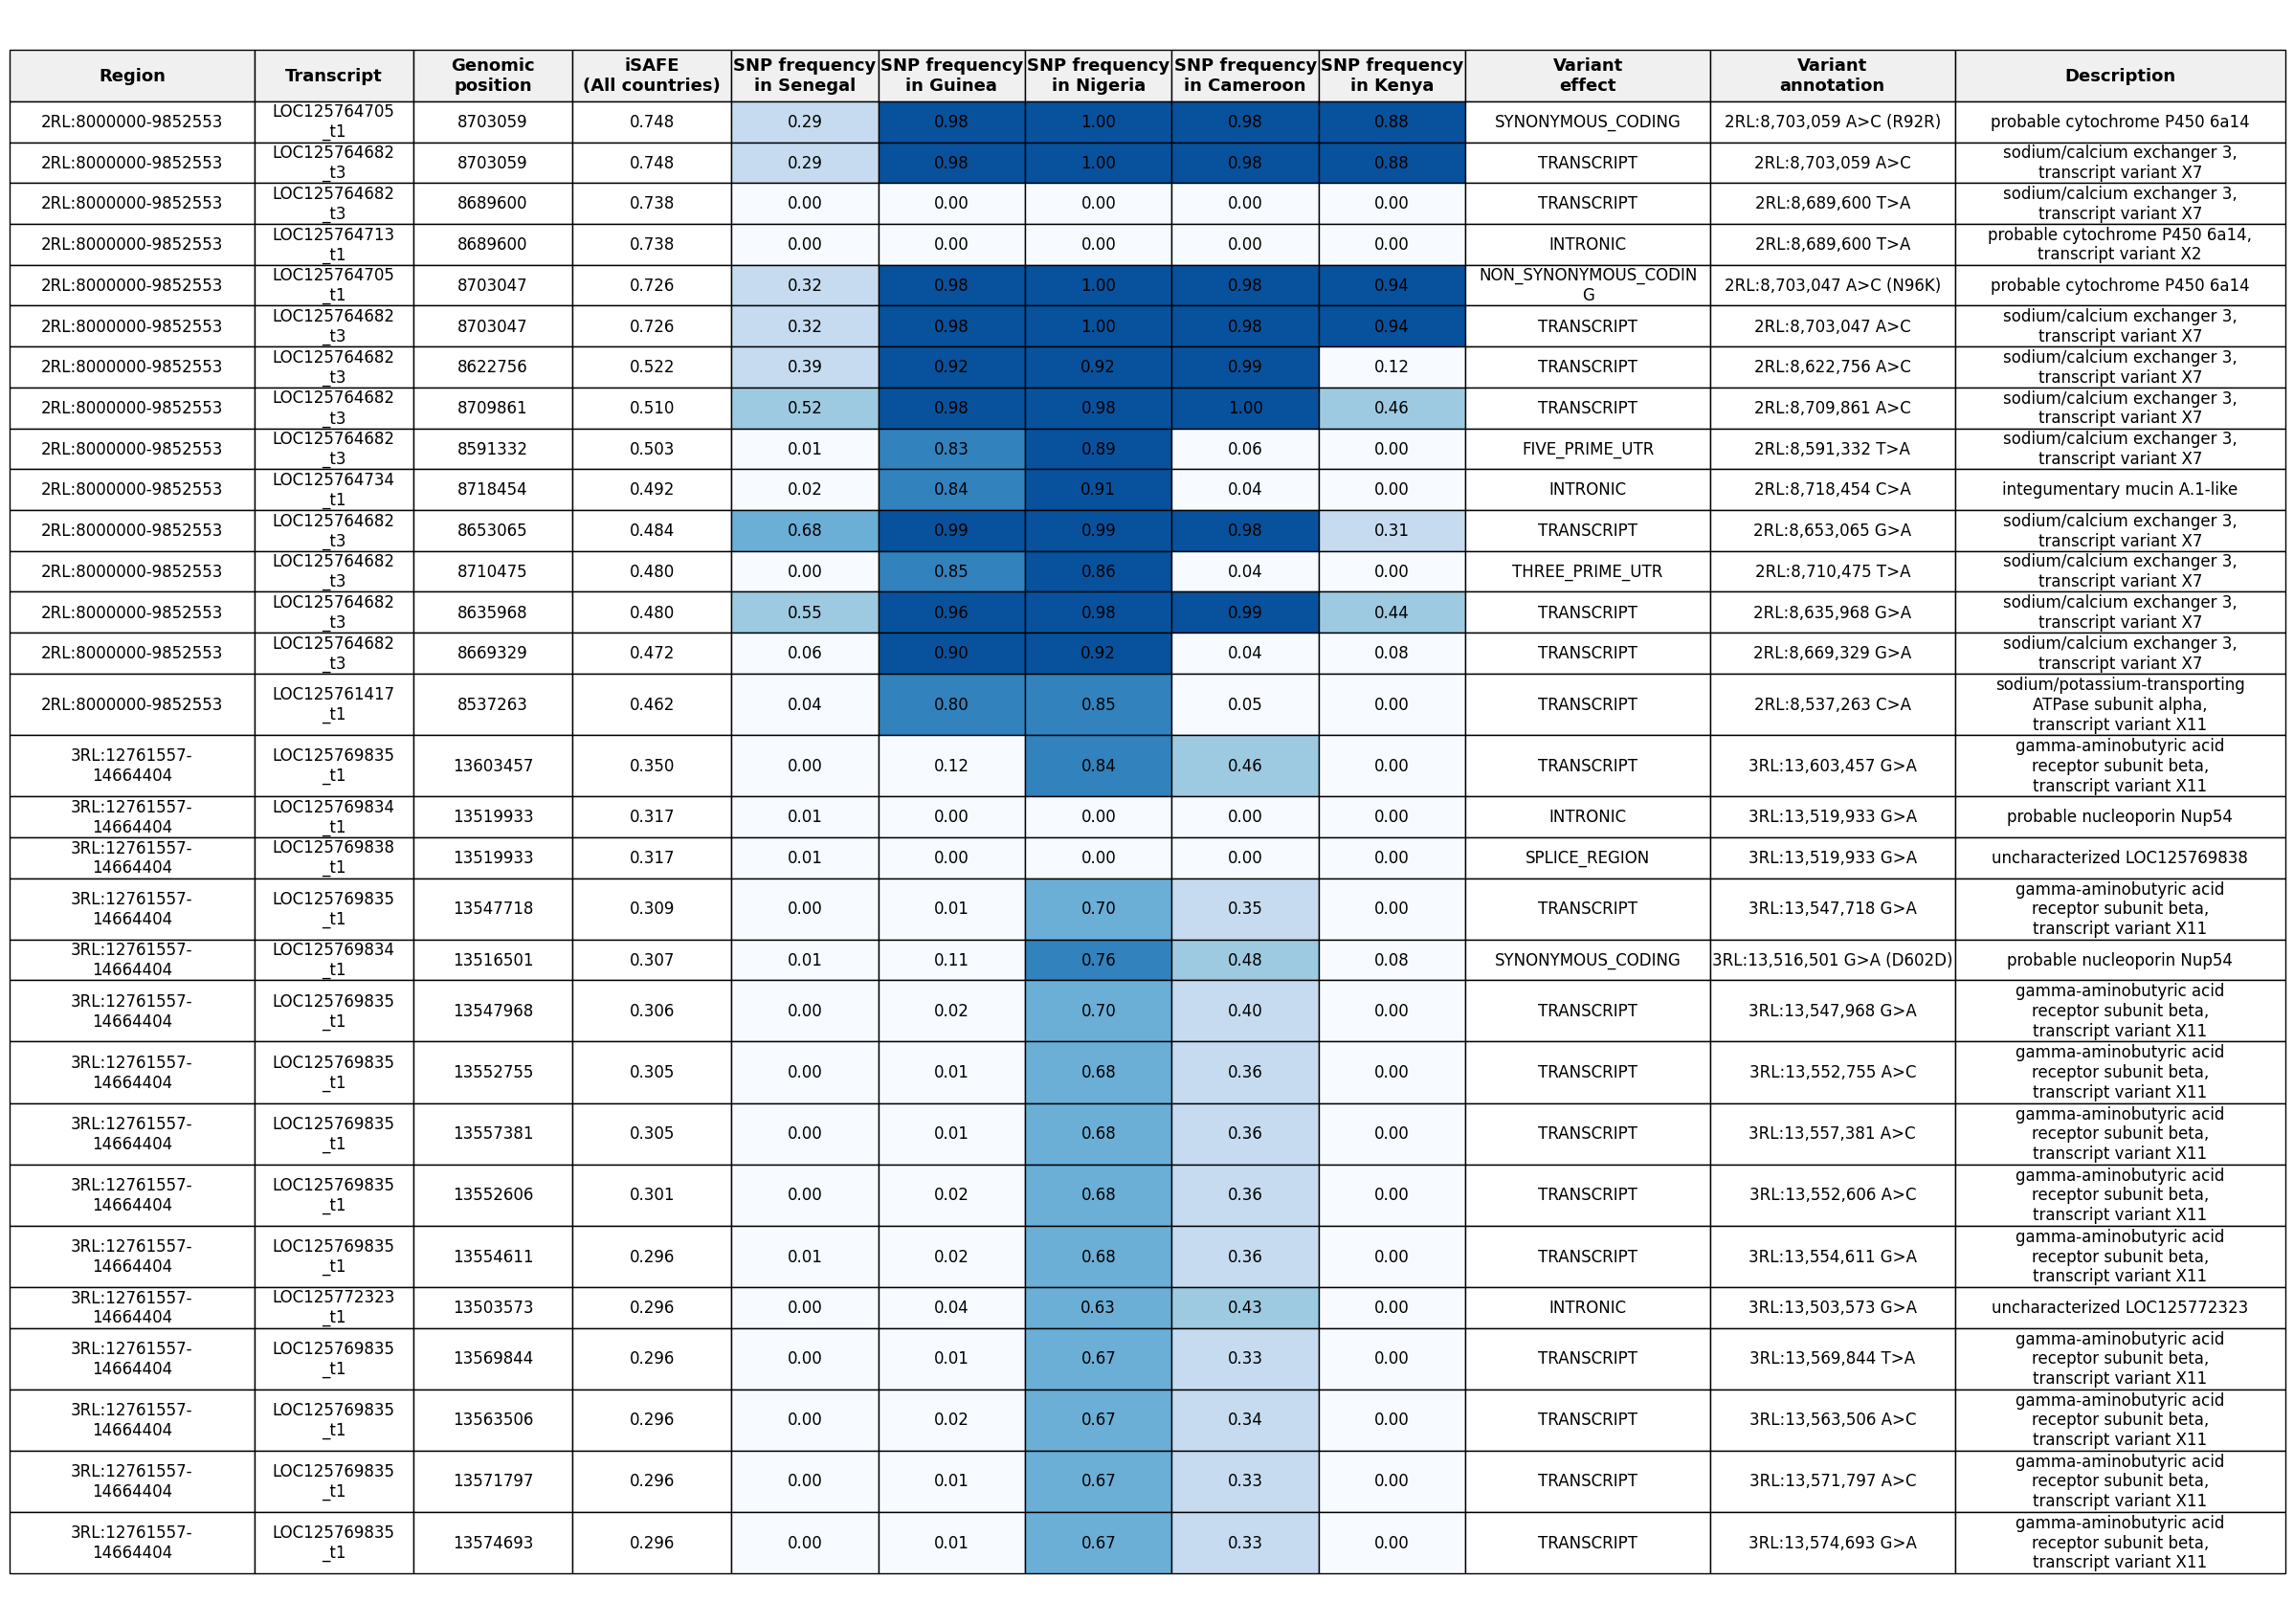

In [45]:
# =========================
# INPUT
# =========================
df = final_top15.copy()

df.rename(columns={"regions_x": "region"}, inplace=True)

# =========================
# COLUMN ORDER
# =========================
cols = [
    "region",
    "transcript",
    "POS",
    "iSAFE_Allcountries",
    "frq_Senegal", "frq_Guinea", "frq_Nigeria", "frq_Cameroon", "frq_Kenya",
    "effect",
    "label",
    "description"
]

tbl = df[cols].copy()

# =========================
# RENAME
# =========================
rename_map = {
    "region": "Region",
    "transcript": "Transcript",
    "description": "Description",
    "POS": "Genomic\nposition",
    "iSAFE_Allcountries": "iSAFE\n(All countries)",
    "frq_Senegal": "SNP frequency\nin Senegal",
    "frq_Guinea": "SNP frequency\nin Guinea",
    "frq_Nigeria": "SNP frequency\nin Nigeria",
    "frq_Cameroon": "SNP frequency\nin Cameroon",
    "frq_Kenya": "SNP frequency\nin Kenya",
    "effect": "Variant\neffect",
    "label": "Variant\nannotation"
}

tbl = tbl.rename(columns=rename_map)

# =========================
# FORMAT NUMBERS
# =========================
freq_cols = [c for c in tbl.columns if "SNP frequency" in c]
freq_numeric = tbl[freq_cols].astype(float).copy()

for col in freq_cols:
    tbl[col] = tbl[col].apply(lambda x: f"{x:.2f}" if pd.notna(x) else "")

tbl["iSAFE\n(All countries)"] = tbl["iSAFE\n(All countries)"].apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else ""
)

tbl["Genomic\nposition"] = tbl["Genomic\nposition"].astype(int).astype(str)

# =========================
# WRAP TEXT
# =========================
def wrap_text(s, width):
    return s if not isinstance(s, str) else "\n".join(textwrap.wrap(s, width))

wrap_specs = {
    "Region": 20,
    "Transcript": 12,
    "Description": 30,
    "Variant\neffect": 20,
}

for col, w in wrap_specs.items():
    tbl[col] = tbl[col].apply(lambda x: wrap_text(x, w))

# =========================
# COLUMN WIDTHS
# =========================
col_widths = []

for col in tbl.columns:
    if col == "Description":
        col_widths.append(0.27)
    elif col in ["Region", "Variant\neffect", "Variant\nannotation"]:
        col_widths.append(0.20)
    elif "SNP frequency" in col:
        col_widths.append(0.12)
    else:
        col_widths.append(0.13)

total = sum(col_widths)
col_widths = [w / total for w in col_widths]

# =========================
# FIGURE
# =========================

max_rows_per_page = 30

tbl_plot = tbl.iloc[:max_rows_per_page]  # TEMP: avoid overflow

fig_height = 0.5 * len(tbl_plot) + 2

fig, ax = plt.subplots(figsize=(24, fig_height))
ax.axis("off")

table = ax.table(
    cellText=tbl_plot.values,
    colLabels=tbl_plot.columns,
    loc="center",   # 🔥 IMPORTANT: change from "upper left"
    cellLoc="center",
    colWidths=col_widths
)

table.auto_set_font_size(False)
table.set_fontsize(12)

# =========================
# ROW HEIGHT
# =========================
def n_lines(s):
    return 1 if not isinstance(s, str) else s.count("\n") + 1

for r in range(len(tbl)):
    max_lines = max(n_lines(tbl.iloc[r][c]) for c in tbl.columns)
    for c in range(len(tbl.columns)):
        table[(r + 1, c)].set_height(
            table[(r + 1, c)].get_height() * max_lines
        )

# =========================
# HEADER STYLE
# =========================
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#f0f0f0")
        cell.set_text_props(weight="bold", fontsize=13)
        cell.set_height(cell.get_height() * 2.5)
        


# =========================
# HEATMAP
# =========================
teal_colors = ["#f7fbfb", "#d9f0f0", "#a6dcd6", "#5fc4bf", "#1f9e9a", "#0b6e6d"]


blue_colors = [
    "#f7fbff",
    "#deebf7",
    "#c6dbef",
    "#9ecae1",
    "#6baed6",
    "#3182bd",
    "#08519c"
]

cmap = ListedColormap(blue_colors)
norm = Normalize(0, 1)

col_idx = {c: i for i, c in enumerate(tbl.columns)}

for r in range(len(tbl)):
    for col in freq_cols:
        val = freq_numeric.iloc[r][freq_cols.index(col)]
        if pd.notna(val):
            table[(r + 1, col_idx[col])].set_facecolor(cmap(norm(val)))

# =========================
# LEFT ALIGN TEXT
# =========================
left_cols = ["Region", "Transcript", "Variant\neffect", "Description"]

for col in left_cols:
    ci = col_idx[col]
    for r in range(len(tbl) + 1):
        table[(r, ci)]._loc = "left"

# =========================
# SAVE
# =========================
plt.tight_layout(pad=0.8)
plt.savefig("isafe_table_updated_blue.pdf", dpi=600)
plt.savefig("isafe_table_updated_blue.svg")

plt.show()

In [7]:
country_cols = [
    c for c in merged.columns
    if c.startswith("iSAFE_") and c != "iSAFE_Allcountries"
]

In [8]:
def get_countries_with_signal(row, cols):
    countries = []
    for c in cols:
        if pd.notna(row[c]):
            countries.append(c.replace("iSAFE_", ""))
    return ", ".join(countries)

In [6]:
import pandas as pd

# -------------------------
# CONFIG
# -------------------------
country_cols = [
    "iSAFE_Senegal",
    "iSAFE_Guinea",
    "iSAFE_Nigeria",
    "iSAFE_Cameroon",
    "iSAFE_Kenya",
]

# ensure numeric ONCE
for c in ["iSAFE_Allcountries"] + country_cols:
    merged[c] = pd.to_numeric(merged[c], errors="coerce")

# -------------------------
# PROCESS
# -------------------------
results = []

for region in merged["regions_x"].dropna().unique():
    
    df_r = merged[merged["regions_x"] == region].copy()
    
    if df_r.empty:
        continue

    # -------------------------
    # Extract countries with signal
    # -------------------------
    df_r["countries_list"] = df_r[country_cols].apply(
        lambda row: [c.replace("iSAFE_", "") for c in country_cols if pd.notna(row[c])],
        axis=1
    )
    
    df_r["countries"] = df_r["countries_list"].apply(lambda x: ",".join(x))
    df_r["n_countries"] = df_r["countries_list"].apply(len)

    # -------------------------
    # Keep shared SNPs (>=2 countries)
    # -------------------------
    df_r = df_r[df_r["n_countries"] >= 2].copy()
    
    if df_r.empty:
        continue

    # -------------------------
    # Ranking: max iSAFE across countries
    # -------------------------
    df_r["max_isafe"] = df_r[country_cols].max(axis=1)

    # -------------------------
    # Top 10 per region
    # -------------------------
    top10 = (
        df_r
        .sort_values("max_isafe", ascending=False)
        .head(10)
        .copy()
    )

    # -------------------------
    # Add metadata
    # -------------------------
    top10["region"] = region

    top10["top_country"] = (
        top10[country_cols]
        .idxmax(axis=1)
        .str.replace("iSAFE_", "", regex=False)
    )

    results.append(top10)

# -------------------------
# Combine all regions
# -------------------------
final_shared_top10 = pd.concat(results, ignore_index=True)



final_shared_top10.head(20)

,Unnamed: 0,regions_x,ID,pass_funestus,frq_Cameroon,frq_Guinea,frq_Kenya,frq_Nigeria,frq_Senegal,max_af,...,iSAFE_Oyo,iSAFE_SaintLouis,iSAFE_Senegal,iSAFE_South,countries_list,countries,n_countries,max_isafe,region,top_country
0,3221844,2RL:8000000-9852553,LOC125764708_t3,True,0.611111,0.094388,0.000000,0.574427,0.105634,0.611111,...,0.440925,NaN,NaN,0.450991,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.450991,2RL:8000000-9852553,Cameroon
1,2168919,2RL:8000000-9852553,LOC125764675_t1,True,0.611111,0.038265,0.041667,0.507605,0.169014,0.611111,...,0.490813,NaN,NaN,0.404157,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.404157,2RL:8000000-9852553,Cameroon
2,3346632,2RL:8000000-9852553,LOC125764708_t3,True,0.598765,0.045918,0.083333,0.517110,0.085714,0.598765,...,0.425897,NaN,NaN,0.393304,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.393304,2RL:8000000-9852553,Cameroon
3,3197073,2RL:8000000-9852553,LOC125764708_t3,True,0.024691,0.553571,0.000000,0.549430,0.070423,0.553571,...,0.450729,NaN,NaN,NaN,"[Guinea, Nigeria]","Guinea,Nigeria",2,0.365856,2RL:8000000-9852553,Nigeria
4,3245652,2RL:8000000-9852553,LOC125764708_t3,True,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.450729,NaN,NaN,0.365564,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.365564,2RL:8000000-9852553,Cameroon
5,2301330,2RL:8000000-9852553,LOC125764675_t1,True,0.000000,0.000000,0.000000,0.001901,0.000000,0.001901,...,0.487320,NaN,NaN,0.260316,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.356948,2RL:8000000-9852553,Nigeria
6,2167500,2RL:8000000-9852553,LOC125764675_t1,True,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,"[Guinea, Nigeria]","Guinea,Nigeria",2,0.352126,2RL:8000000-9852553,Nigeria
7,2157846,2RL:8000000-9852553,LOC125764675_t1,True,0.475309,0.520408,0.000000,0.036122,0.000000,0.520408,...,NaN,NaN,NaN,0.346637,"[Guinea, Cameroon]","Guinea,Cameroon",2,0.346637,2RL:8000000-9852553,Cameroon
8,3231258,2RL:8000000-9852553,LOC125764708_t3,True,0.493827,0.048469,0.395833,0.515209,0.063380,0.515209,...,0.426679,NaN,NaN,0.315970,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.332226,2RL:8000000-9852553,Nigeria
9,3231264,2RL:8000000-9852553,LOC125764708_t3,True,0.493827,0.048469,0.395833,0.513308,0.084507,0.513308,...,NaN,NaN,NaN,0.315970,"[Nigeria, Cameroon]","Nigeria,Cameroon",2,0.332226,2RL:8000000-9852553,Nigeria


In [7]:
cols_to_drop = [c for c in final_shared_top10.columns if c.startswith("iSAFE_")]

final_shared_top10 = final_shared_top10.drop(columns=cols_to_drop)

In [47]:
final_shared_top10.to_csv("final_top10_shared_snps_per_region_isafe_subcountries.csv", index=False)

/tmp/ipykernel_1693505/2303735907.py:179: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  val = freq_numeric.iloc[r][freq_cols.index(col)]


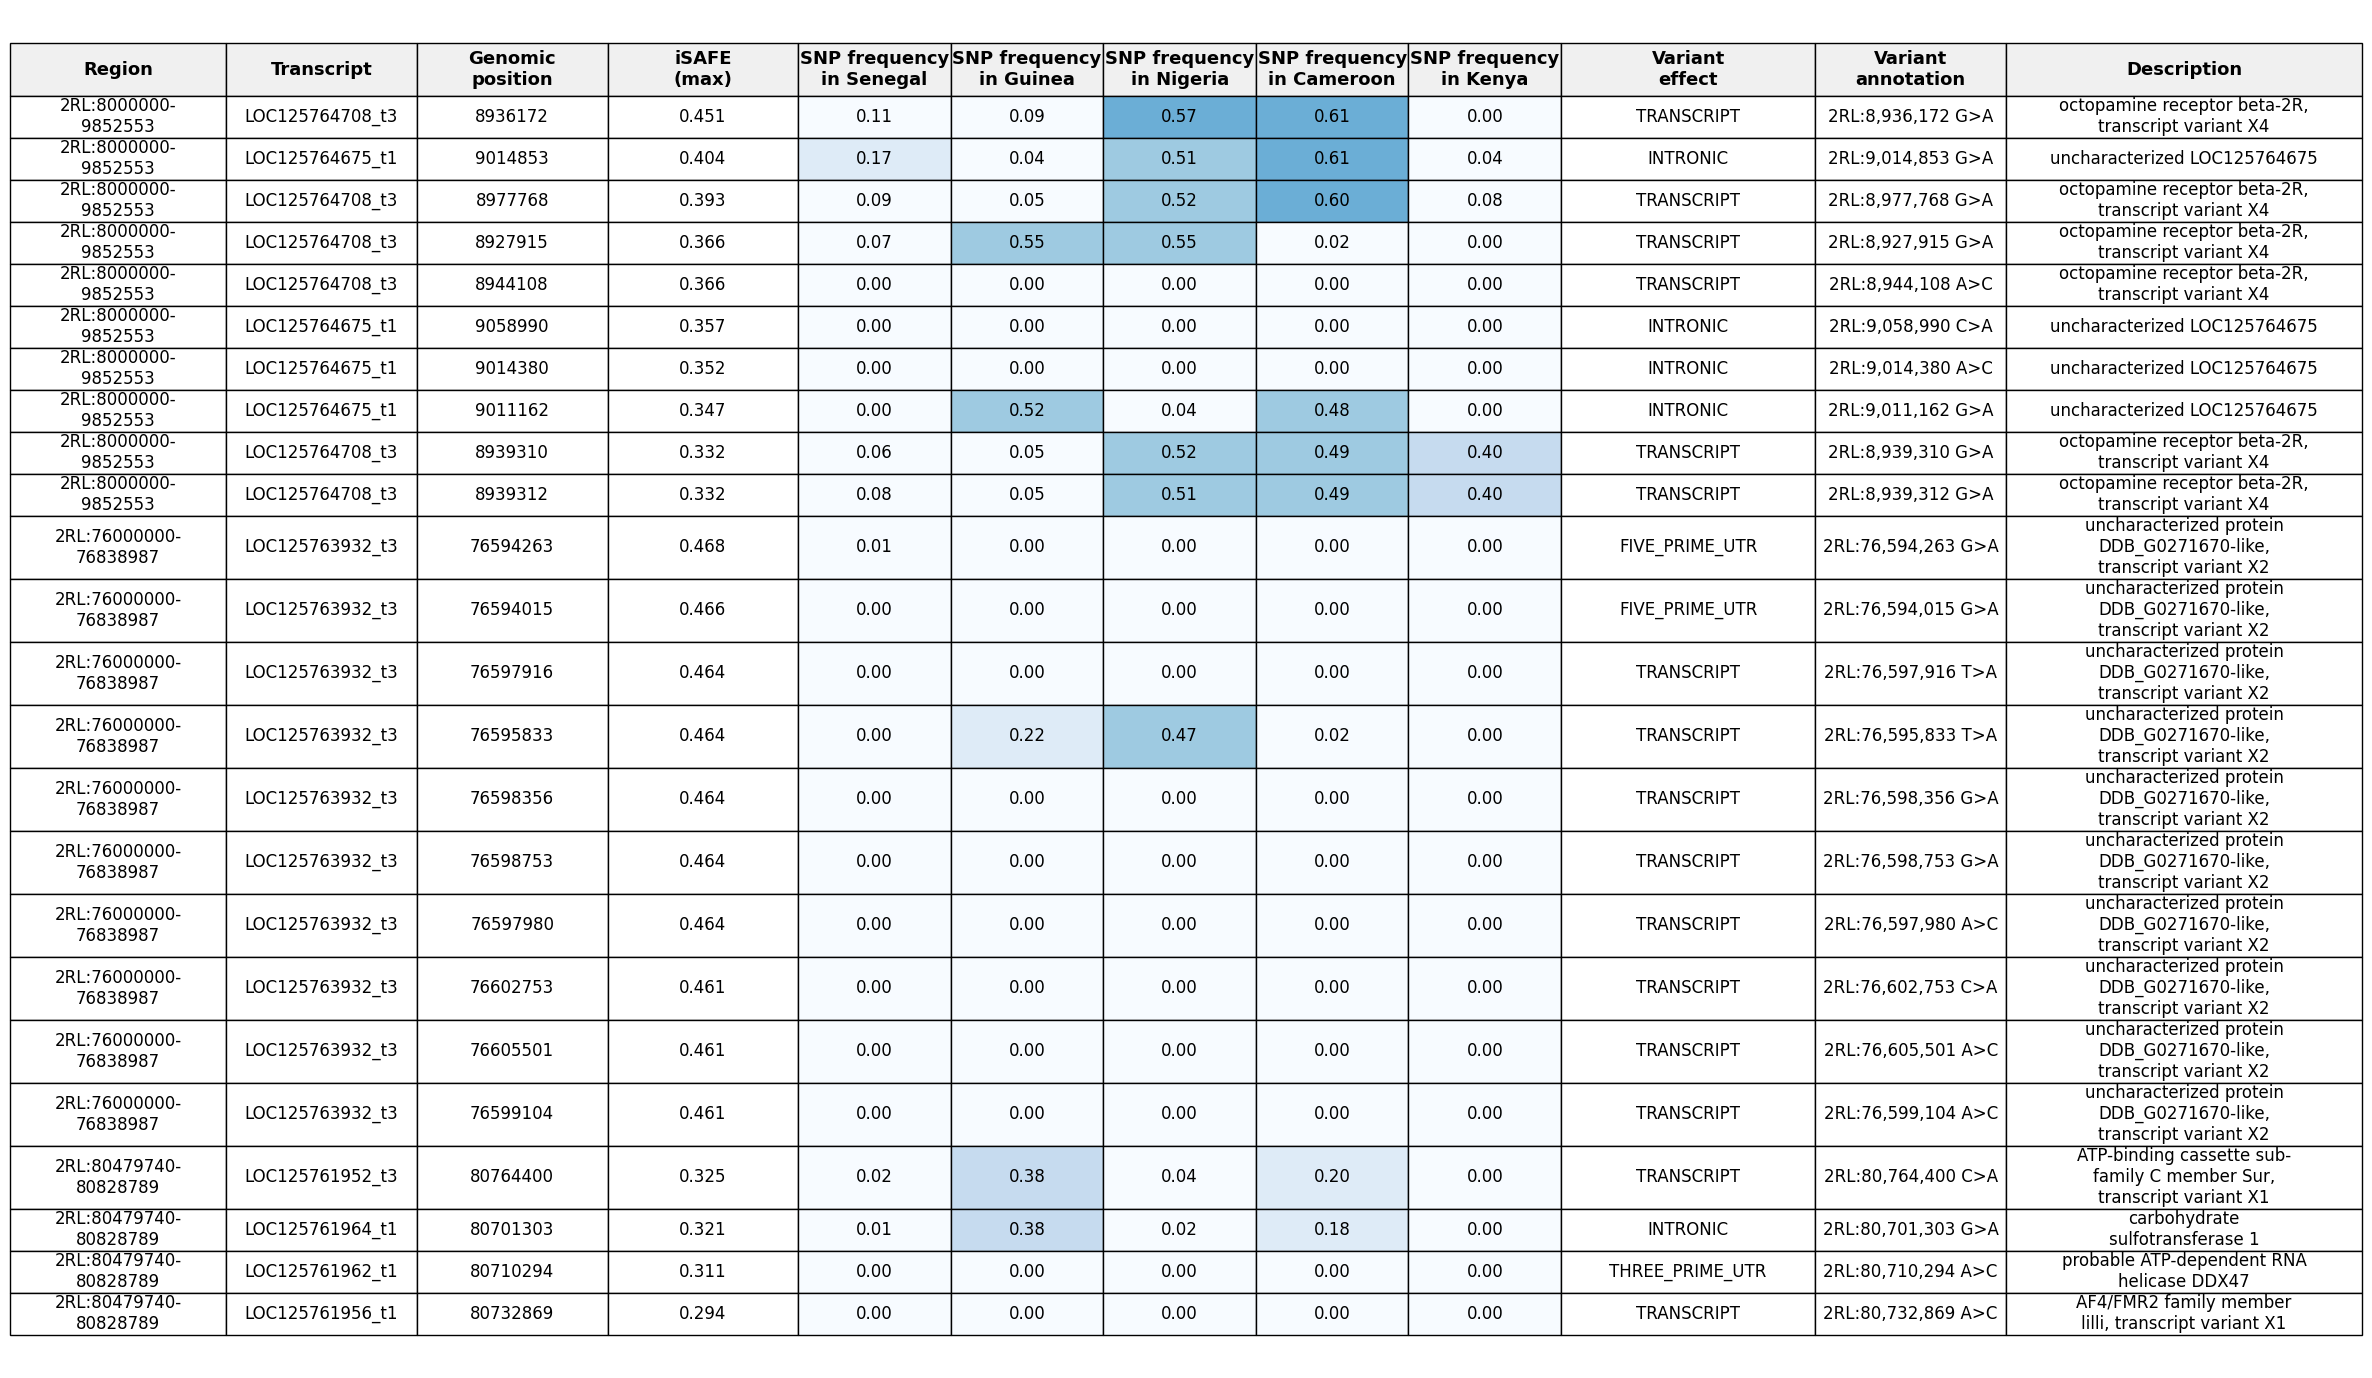

In [42]:
# =========================
# INPUT
# =========================
df = final_shared_top10.copy()

# =========================
# COLUMN ORDER
# =========================
cols = [
    "region",
    "transcript",
    "POS",
    "max_isafe",
    "frq_Senegal", "frq_Guinea", "frq_Nigeria", "frq_Cameroon", "frq_Kenya",
    "effect",
    "label",
    "description"
]

tbl = df[cols].copy()

# =========================
# RENAME
# =========================
rename_map = {
    "region": "Region",
    "transcript": "Transcript",
    "description": "Description",
    "POS": "Genomic\nposition",
    "max_isafe": "iSAFE\n(max)",
    "frq_Senegal": "SNP frequency\nin Senegal",
    "frq_Guinea": "SNP frequency\nin Guinea",
    "frq_Nigeria": "SNP frequency\nin Nigeria",
    "frq_Cameroon": "SNP frequency\nin Cameroon",
    "frq_Kenya": "SNP frequency\nin Kenya",
    "effect": "Variant\neffect",
    "label": "Variant\nannotation"
}

tbl = tbl.rename(columns=rename_map)

# =========================
# FORMAT NUMBERS
# =========================
freq_cols = [c for c in tbl.columns if "SNP frequency" in c]

# keep numeric copy for coloring
freq_numeric = tbl[freq_cols].apply(pd.to_numeric, errors="coerce")

# format display (force 2 decimals including 0.00)
for col in freq_cols:
    tbl[col] = freq_numeric[col].apply(
        lambda x: f"{x:.2f}" if pd.notna(x) else ""
    )

# iSAFE formatting
tbl["iSAFE\n(max)"] = pd.to_numeric(tbl["iSAFE\n(max)"], errors="coerce").apply(
    lambda x: f"{x:.3f}" if pd.notna(x) else ""
)

# genomic position
tbl["Genomic\nposition"] = tbl["Genomic\nposition"].astype(int).astype(str)

# =========================
# WRAP TEXT
# =========================
def wrap_text(s, width):
    return s if not isinstance(s, str) else "\n".join(textwrap.wrap(s, width))

wrap_specs = {
    "Region": 18,
    "Transcript": 16,
    "Description": 28,
    "Variant\neffect": 18,
}

for col, w in wrap_specs.items():
    tbl[col] = tbl[col].apply(lambda x: wrap_text(x, w))

# =========================
# COLUMN WIDTHS
# =========================
col_widths = []

for col in tbl.columns:
    if col == "Description":
        col_widths.append(0.28)
    elif col =="Region":
        col_widths.append(0.17)
    elif col == "Variant\neffect":
        col_widths.append(0.20)
    elif "SNP frequency" in col:
        col_widths.append(0.12)
    else:
        col_widths.append(0.15)

total = sum(col_widths)
col_widths = [w / total for w in col_widths]

# =========================
# FIGURE 
# =========================

max_rows_per_page = 30

tbl_plot = tbl.iloc[:max_rows_per_page]  # TEMP: avoid overflow

fig_height = 0.5 * len(tbl_plot) + 2

fig, ax = plt.subplots(figsize=(24, fig_height))
ax.axis("off")

table = ax.table(
    cellText=tbl_plot.values,
    colLabels=tbl_plot.columns,
    loc="center",   # 🔥 IMPORTANT: change from "upper left"
    cellLoc="center",
    colWidths=col_widths
)

table.auto_set_font_size(False)
table.set_fontsize(12)


# =========================
# ROW HEIGHT
# =========================
def n_lines(s):
    return 1 if not isinstance(s, str) else s.count("\n") + 1

for r in range(len(tbl)):
    max_lines = max(n_lines(tbl.iloc[r][c]) for c in tbl.columns)
    for c in range(len(tbl.columns)):
        table[(r + 1, c)].set_height(
            table[(r + 1, c)].get_height() * max_lines
        )

# =========================
# HEADER STYLE
# =========================
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#f0f0f0")
        cell.set_text_props(weight="bold", fontsize=13)  # bigger font
        cell.set_height(cell.get_height() * 2.5)  # was 1.6 → too small

# =========================
# TEAL HEATMAP (IMPROVED)
# =========================
teal_colors = [
    "#f7fbfb",
    "#d9f0f0",
    "#a6dcd6",
    "#5fc4bf",
    "#1f9e9a",
    "#0b6e6d"
]


blue_colors = [
    "#f7fbff",
    "#deebf7",
    "#c6dbef",
    "#9ecae1",
    "#6baed6",
    "#3182bd",
    "#08519c"
]

cmap = ListedColormap(blue_colors)
norm = Normalize(0, 1)

col_idx = {c: i for i, c in enumerate(tbl.columns)}

for r in range(len(tbl)):
    for col in freq_cols:
        val = freq_numeric.iloc[r][freq_cols.index(col)]
        if pd.notna(val):
            cell = table[(r + 1, col_idx[col])]
            cell.set_facecolor(cmap(norm(val)))
            cell.set_text_props(ha="center", va="center")

# =========================
# LEFT ALIGN TEXT
# =========================
left_cols = ["Region", "Transcript", "Variant\neffect", "Description"]

for col in left_cols:
    ci = col_idx[col]
    for r in range(len(tbl) + 1):
        table[(r, ci)]._loc = "left"

# =========================
# SAVE (NO TIGHT_LAYOUT BUG)
# =========================
plt.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.01)

plt.savefig("isafe_table_per_countries_blue.pdf", dpi=600)
plt.savefig("isafe_table_per_countries_blue.png", dpi=300)

plt.show()